# Support-Vector Networks (Cortes & Vapnik, 1995) — Reprodução dos experimentos

Este notebook busca reproduzir os experimentos do artigo:

| Parte | O que reproduz no artigo |
|---|---|
| 1 | Solver próprio do **dual** (hiperplano ótimo + margem suave) e verificação dos exercícios do Apêndice A |
| 2 | **Seção 2**: treinamento incremental por blocos (*chunking*) |
| 3 | **Seção 6.1 / Fig. 5**: experimentos no plano com polinômio de grau 2 |
| 4 | **Seção 6.2.1 / Tabela 2**: dígitos USPS, polinômios de grau 1 a 7 |
| 5 | **Eq. (5)**: limite de generalização via nº de vetores de suporte |
| 6 | **Seção 5.3**: efeito do parâmetro C (controle de capacidade) |
| 7 | **Seção 6.2.2 / Tabela 3 / Fig. 9**: base NIST (MNIST), grau 4, comparação com linear e k-NN |
| 8 | Observação do artigo: **permutação aleatória dos pixels** não altera o resultado |



**Observações de fidelidade:** o artigo usa o kernel `K(u,v) = (u·v + 1)^d`. Aqui
`(γ·u·v + 1)^d` com `γ = 1/n` (apenas reescala as entradas, mantém a mesma família de máquinas
e evita problemas numéricos). O pré-processamento do artigo (centralização, correção de inclinação
e suavização gaussiana σ = 0,75) é parcialmente reproduzido (suavização apenas).

In [1]:
# ===== Configuração geral =====
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy.optimize import minimize
from scipy.ndimage import gaussian_filter
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_digits, fetch_openml
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

# ---- Parâmetros ajustáveis (reduza para rodar mais rápido) ----
FAST = True            # True: usa subconjuntos menores (recomendado no Colab gratuito)
N_TRAIN_USPS = 3000 if FAST else None   # None = usa os 7.291 de treino
N_TRAIN_MNIST = 6000 if FAST else 60000
N_TEST_MNIST = 3000 if FAST else 10000
DEGREES = [1, 2, 3, 4, 5, 6, 7]
C_LARGE = 100.0        # "C suficientemente grande" (margem suave quase rígida)

## Parte 1 — Solver próprio do problema dual

Busca resolver

$$\max_\Lambda\; W(\Lambda)=\Lambda^T\mathbf 1-\tfrac12\Lambda^T D\Lambda\quad \text{s.a.}\quad 0\le\Lambda\le C\mathbf 1,\; \Lambda^T Y=0,$$

com $D_{ij}=y_iy_jK(x_i,x_j)$. Com $C\to\infty$ recupera-se o hiperplano ótimo (Seção 2). Também
implementamos a variante de mínimos quadrados do artigo (Eq. 67), que equivale a trocar
$D$ por $D+I/C$ e usar apenas $\Lambda\ge 0$.

In [2]:
def poly_kernel(d, gamma=1.0):
    """K(u,v) = (gamma * u.v + 1)^d  (Eq. 37/39 do artigo, com gamma=1 no original)."""
    return lambda A, B: (gamma * (A @ B.T) + 1.0) ** d

def rbf_kernel(sigma):
    def k(A, B):
        d2 = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T
        return np.exp(-np.maximum(d2, 0) / sigma**2)
    return k

class SoftMarginSVN:
    """Support-vector network resolvendo o dual com SLSQP (adequado para ~ até 500 amostras).

    variant = "box"  -> F(u)=u : 0 <= alpha <= C                (formulação moderna, k=1)
    variant = "ls"   -> Eq. (67): D + I/C, alpha >= 0           (erros ao quadrado)
    """
    def __init__(self, kernel, C=np.inf, variant="box", tol=1e-6):
        self.kernel, self.C, self.variant, self.tol = kernel, C, variant, tol

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        n = len(y)
        K = self.kernel(X, X)
        Q = (y[:, None] * y[None, :]) * K
        if self.variant == "ls":
            Q = Q + np.eye(n) / self.C
            ub = np.inf
        else:
            ub = self.C
        res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(n),
                       jac=lambda a: Q @ a - 1.0, method="SLSQP",
                       bounds=[(0, None if np.isinf(ub) else ub)] * n,
                       constraints=[{"type": "eq", "fun": lambda a: a @ y, "jac": lambda a: y}],
                       options={"maxiter": 500, "ftol": 1e-12})
        a = res.x
        a[a < self.tol] = 0.0
        self.alpha, self.X, self.y, self.n_ = a, X, y, n
        sv = a > self.tol
        # bias: média sobre vetores "livres" (0 < alpha < C) -> y_i f(x_i) = 1
        if self.variant == "ls":
            free = sv                      # xi_i = alpha_i / C  ->  y_i f(x_i) = 1 - alpha_i/C
            f0 = K @ (a * y)
            self.b = np.mean(y[free] * (1 - a[free] / self.C) - f0[free])
        else:
            free = sv & (a < ub - self.tol) if not np.isinf(ub) else sv
            if free.sum() == 0:            # todos no limite: ponto médio das cotas de b
                f0 = K @ (a * y)
                lo = np.max((y - f0)[y < 0]) if np.any(y < 0) else 0
                hi = np.min((y - f0)[y > 0]) if np.any(y > 0) else 0
                self.b = 0.5 * (lo + hi)
            else:
                f0 = K @ (a * y)
                self.b = np.mean(y[free] - f0[free])
        self.sv_mask = sv
        return self

    def decision_function(self, Xn):
        K = self.kernel(np.asarray(Xn, float), self.X)
        return K @ (self.alpha * self.y) + self.b

    def predict(self, Xn):
        return np.where(self.decision_function(Xn) >= 0, 1, -1)

    @property
    def w_norm2(self):  # w.w = alpha^T D alpha  (espaço de características)
        K = self.kernel(self.X, self.X)
        return float((self.alpha * self.y) @ K @ (self.alpha * self.y))

    @property
    def n_sv(self):
        return int(self.sv_mask.sum())

### Verificação com os exercícios resolvidos (Apêndice A)

In [3]:
lin = lambda A, B: A @ B.T

# Exercício 1: x1=3 (+1), x2=1 (-1)  ->  alpha=1/2, w=1, b=-2, W=1/2=2/rho^2
X1 = np.array([[3.0], [1.0]]); y1 = np.array([1, -1])
m = SoftMarginSVN(lin, C=np.inf).fit(X1, y1)
w = (m.alpha * y1) @ X1
print("Ex.1  alpha =", m.alpha.round(4), "| w =", w.round(4), "| b =", round(m.b, 4))
rho = 2 / np.linalg.norm(w)
W = m.alpha.sum() - 0.5 * m.w_norm2
print(f"      W(Λ0) = {W:.4f}  e  2/ρ0² = {2/rho**2:.4f}  (devem coincidir)")

# Exercício 2: A=(1,1)+, B=(3,3)+, C=(-1,-1)-  ->  alpha_B = 0, w=(1/2,1/2), b=0
X2 = np.array([[1, 1], [3, 3], [-1, -1]], float); y2 = np.array([1, 1, -1])
m = SoftMarginSVN(lin, C=np.inf).fit(X2, y2)
print("Ex.2  alpha =", m.alpha.round(4), "| w =", ((m.alpha * y2) @ X2).round(4), "| b =", round(m.b, 4))

# Exercício 4: margem suave (k=1); C=1/4  ->  w = 1/2
m = SoftMarginSVN(lin, C=0.25, variant="box").fit(X1, y1)
print("Ex.4  C=1/4: alpha =", m.alpha.round(4), "| w =", ((m.alpha * y1) @ X1).round(4))

# Exercício 5: mínimos quadrados  ->  alpha = C/(2C+1)
for C in [0.5, 5.0]:
    m = SoftMarginSVN(lin, C=C, variant="ls").fit(X1, y1)
    print(f"Ex.5  C={C}: alpha = {m.alpha[0]:.4f}  (teoria {C/(2*C+1):.4f})")

# Conferência cruzada com o scikit-learn
rs = np.random.default_rng(1)
Xt = np.vstack([rs.normal(-1.5, 1, (30, 2)), rs.normal(1.5, 1, (30, 2))]); yt = np.r_[-np.ones(30), np.ones(30)]
mine = SoftMarginSVN(poly_kernel(2), C=10).fit(Xt, yt)
ref = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=10).fit(Xt, yt)
print("\nSolver próprio  : #SV =", mine.n_sv, "| acc =", (mine.predict(Xt) == yt).mean())
print("scikit-learn SVC: #SV =", ref.n_support_.sum(), "| acc =", ref.score(Xt, yt))

Ex.1  alpha = [0.5 0.5] | w = [1.] | b = -2.0
      W(Λ0) = 0.5000  e  2/ρ0² = 0.5000  (devem coincidir)
Ex.2  alpha = [0.25 0.   0.25] | w = [0.5 0.5] | b = 0.0
Ex.4  C=1/4: alpha = [0.25 0.25] | w = [0.5]
Ex.5  C=0.5: alpha = 0.2500  (teoria 0.2500)
Ex.5  C=5.0: alpha = 0.4545  (teoria 0.4545)

Solver próprio  : #SV = 4 | acc = 1.0
scikit-learn SVC: #SV = 4 | acc = 1.0


## Parte 2 — Treinamento incremental por blocos (Seção 2 do artigo)

Divide-se o conjunto em porções. Resolve-se o QP da primeira; a seguir, junta-se
**os vetores de suporte** da solução atual com **os vetores da próxima porção que violam**
$y_i(w\cdot x_i+b)\ge 1$, e resolve-se novamente. Repete-se até cobrir tudo.

In [4]:
def chunking_fit(X, y, kernel, C, n_chunks=5, tol=1e-3, max_passes=6, verbose=True):
    """Esquema da Seção 2: blocos sequenciais + passagens extras até não haver violadores
    (a passagem extra é necessária com margem suave, onde pontos descartados cedo podem voltar a violar)."""
    idx = np.array_split(rng.permutation(len(y)), n_chunks)
    keep = idx[0]
    model = SoftMarginSVN(kernel, C=C).fit(X[keep], y[keep])
    for t, part in enumerate(idx[1:], start=2):
        viol = part[y[part] * model.decision_function(X[part]) < 1 - tol]
        keep = np.unique(np.r_[keep[model.sv_mask], viol])
        model = SoftMarginSVN(kernel, C=C).fit(X[keep], y[keep])
        if verbose:
            print(f"  bloco {t}: QP com {len(keep):3d} pontos | #SV = {model.n_sv:3d}")
    for p in range(1, max_passes + 1):
        allv = np.where(y * model.decision_function(X) < 1 - tol)[0]
        new = np.setdiff1d(allv, keep)               # violadores fora do conjunto de trabalho
        if len(new) == 0:
            break
        keep = np.unique(np.r_[keep[model.sv_mask], allv])
        model = SoftMarginSVN(kernel, C=C).fit(X[keep], y[keep])
        if verbose:
            print(f"  passagem extra {p}: {len(new)} novos violadores | QP com {len(keep):3d} pontos | #SV = {model.n_sv:3d}")
    return model, keep

Xc = np.vstack([rng.normal(-1.2, 1, (150, 2)), rng.normal(1.2, 1, (150, 2))])
yc = np.r_[-np.ones(150), np.ones(150)]
print("Chunking:")
m_chunk, kept = chunking_fit(Xc, yc, poly_kernel(2), C=10, n_chunks=5)
print("\nSolução completa (QP único com 300 pontos):")
m_full = SoftMarginSVN(poly_kernel(2), C=10).fit(Xc, yc)
print(f"  #SV = {m_full.n_sv}")
agree = (m_chunk.predict(Xc) == m_full.predict(Xc)).mean()
print(f"\nConcordância das predições chunking vs. completo: {agree:.3f}")
print(f"Acurácia no treino: chunking={np.mean(m_chunk.predict(Xc)==yc):.3f} | completo={np.mean(m_full.predict(Xc)==yc):.3f}")
print(f"Maior QP resolvido no chunking: {len(kept)} variáveis (contra 300).")

Chunking:
  bloco 2: QP com  11 pontos | #SV =  10
  bloco 3: QP com  64 pontos | #SV =  19
  bloco 4: QP com  36 pontos | #SV =  22
  bloco 5: QP com  34 pontos | #SV =  29
  passagem extra 1: 104 novos violadores | QP com 133 pontos | #SV =  40
  passagem extra 2: 2 novos violadores | QP com  42 pontos | #SV =  39

Solução completa (QP único com 300 pontos):
  #SV = 39

Concordância das predições chunking vs. completo: 1.000
Acurácia no treino: chunking=0.957 | completo=0.957
Maior QP resolvido no chunking: 42 variáveis (contra 300).


## Parte 3 — Experimentos no plano (Seção 6.1 / Figura 5)

Duas classes (bolinhas pretas e brancas) e polinômio de grau 2.
**Círculo duplo = padrão de suporte**, **cruz = erro de treinamento**.

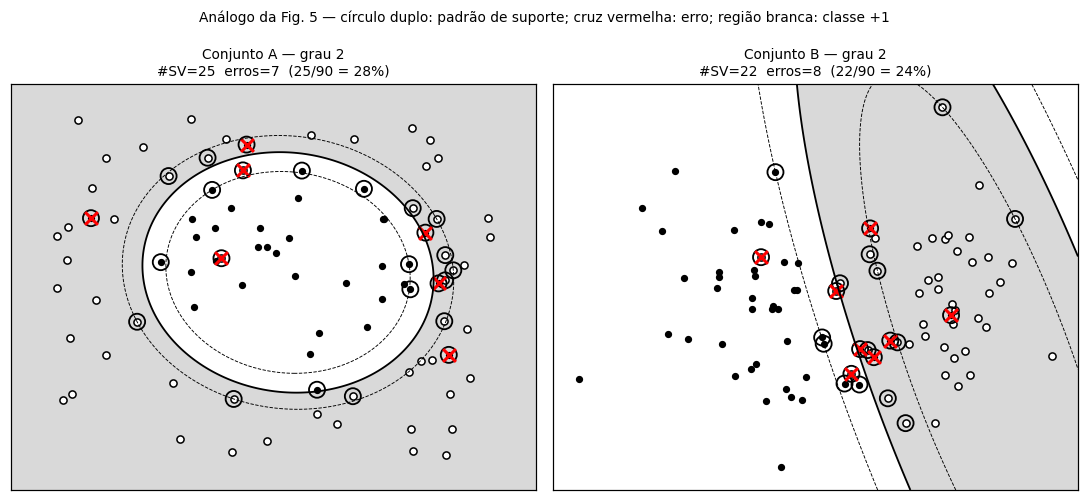

In [5]:
def plot_boundary(ax, model, X, y, title):
    gx = np.linspace(X[:, 0].min() - .3, X[:, 0].max() + .3, 220)
    gy = np.linspace(X[:, 1].min() - .3, X[:, 1].max() + .3, 220)
    GX, GY = np.meshgrid(gx, gy)
    Z = model.decision_function(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)
    ax.contourf(GX, GY, Z, levels=[-1e9, 0, 1e9], colors=["#d9d9d9", "#ffffff"])
    ax.contour(GX, GY, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[.6, 1.2, .6])
    pos, neg = y > 0, y < 0
    ax.scatter(*X[pos].T, c="k", s=14)
    ax.scatter(*X[neg].T, facecolors="white", edgecolors="k", s=22)
    sv = model.sv_mask
    ax.scatter(*X[sv].T, facecolors="none", edgecolors="k", s=110, linewidths=1.2)
    err = y * model.decision_function(X) < 0
    ax.scatter(*X[err].T, marker="x", c="r", s=70, linewidths=2)
    ax.set_title(f"{title}\n#SV={sv.sum()}  erros={err.sum()}  ({sv.sum()}/{len(y)} = {sv.mean():.0%})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

# Conjunto A: região circular com ruído de rótulo
nA = 90
XA = rng.uniform(-1.5, 1.5, (nA, 2)); yA = np.where((XA**2).sum(1) < 1.0, 1, -1)
flip = rng.choice(nA, 4, replace=False); yA[flip] *= -1
# Conjunto B: duas nuvens sobrepostas
XB = np.vstack([rng.normal([-.8, 0], [.7, .9], (45, 2)), rng.normal([.8, 0], [.7, .9], (45, 2))])
yB = np.r_[np.ones(45), -np.ones(45)]

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (X, y, nm) in zip(axs, [(XA, yA, "Conjunto A"), (XB, yB, "Conjunto B")]):
    mdl = SoftMarginSVN(poly_kernel(2), C=100).fit(X, y)
    plot_boundary(ax, mdl, X, y, f"{nm} — grau 2")
plt.suptitle("Análogo da Fig. 5 — círculo duplo: padrão de suporte; cruz vermelha: erro; região branca: classe +1", fontsize=9)
plt.tight_layout(); plt.show()

## Parte 4 — Dígitos manuscritos USPS (Seção 6.2.1 / Tabela 2)

Dez classificadores "um contra todos" (cada hipersuperfície usa o mesmo kernel e o mesmo pré-processamento);
a classe prevista é a de **maior saída**. A dimensão do espaço de características de grau $d$ em $n$ dimensões
é $\binom{n+d}{d}$ (o artigo reporta valores aproximados da mesma ordem).

Base: USPS (OpenML) | treino=3000 teste=2007 | dimensão de entrada n=256


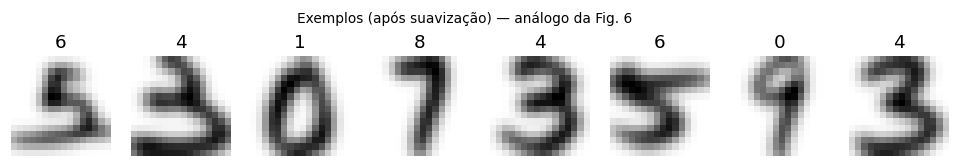

In [6]:
def load_usps():
    try:
        d = fetch_openml("usps", version=1, as_frame=False, parser="auto")
        X = d.data.astype(float); y = d.target.astype(int) % 10  # rótulo 10 -> dígito 0
        X = np.clip(X, -1, 1)
        # divisão original: 7.291 treino / 2.007 teste
        return X[:7291], y[:7291], X[7291:], y[7291:], (16, 16), "USPS (OpenML)"
    except Exception as e:
        print("Falha ao baixar USPS (", type(e).__name__, "). Usando load_digits (8x8).")
        d = load_digits(); X = d.data / 8.0 - 1.0
        Xtr, Xte, ytr, yte = train_test_split(X, d.target, test_size=0.3, random_state=0, stratify=d.target)
        return Xtr, ytr, Xte, yte, (8, 8), "load_digits 8x8 (alternativa)"

def smooth(X, shape, sigma=0.75):
    return np.array([gaussian_filter(x.reshape(shape), sigma).ravel() for x in X])

Xtr, ytr, Xte, yte, SHAPE, NAME = load_usps()
if N_TRAIN_USPS and len(ytr) > N_TRAIN_USPS:
    sel = rng.choice(len(ytr), N_TRAIN_USPS, replace=False); Xtr, ytr = Xtr[sel], ytr[sel]
Xtr_s, Xte_s = smooth(Xtr, SHAPE), smooth(Xte, SHAPE)      # pré-processamento do artigo
n_feat = Xtr_s.shape[1]
print(f"Base: {NAME} | treino={len(ytr)} teste={len(yte)} | dimensão de entrada n={n_feat}")

fig, axs = plt.subplots(1, 8, figsize=(11, 1.8))
for a, i in zip(axs, range(8)):
    a.imshow(Xtr_s[i].reshape(SHAPE), cmap="gray_r"); a.set_title(str(ytr[i])); a.axis("off")
plt.suptitle("Exemplos (após suavização) — análogo da Fig. 6", fontsize=9); plt.show()

In [7]:
def ovr_poly(d, C=C_LARGE, n=n_feat):
    return OneVsRestClassifier(SVC(kernel="poly", degree=d, gamma=1.0 / n, coef0=1.0, C=C, cache_size=500))

def sv_stats(clf):
    return np.mean([e.n_support_.sum() for e in clf.estimators_])

rows = []
for d in DEGREES:
    t0 = time.time()
    clf = ovr_poly(d).fit(Xtr_s, ytr)
    err = 100 * (1 - clf.score(Xte_s, yte))
    nsv = sv_stats(clf)
    dim = comb(n_feat + d, d)
    rows.append((d, err, nsv, dim, time.time() - t0))
    print(f"grau {d}: erro={err:5.2f}%  SV médios/classificador={nsv:6.1f}  dim={dim:.2e}  ({rows[-1][-1]:.1f}s)")

print("\nTABELA 2 (reprodução)")
print(f"{'Grau':>5} {'Erro bruto %':>13} {'Vetores de suporte':>19} {'Dim. espaço de caract.':>24}")
for d, e, s, dim, _ in rows:
    print(f"{d:>5} {e:>13.2f} {s:>19.0f} {dim:>24.2e}")

grau 1: erro= 8.97%  SV médios/classificador= 128.5  dim=2.57e+02  (1.0s)
grau 2: erro= 6.53%  SV médios/classificador= 108.2  dim=3.32e+04  (0.9s)
grau 3: erro= 6.78%  SV médios/classificador= 101.3  dim=2.86e+06  (0.8s)
grau 4: erro= 6.38%  SV médios/classificador= 109.2  dim=1.86e+08  (1.0s)
grau 5: erro= 6.13%  SV médios/classificador= 114.2  dim=9.71e+09  (1.2s)
grau 6: erro= 5.83%  SV médios/classificador= 119.4  dim=4.24e+11  (1.3s)
grau 7: erro= 5.63%  SV médios/classificador= 126.4  dim=1.59e+13  (0.9s)

TABELA 2 (reprodução)
 Grau  Erro bruto %  Vetores de suporte   Dim. espaço de caract.
    1          8.97                 128                 2.57e+02
    2          6.53                 108                 3.32e+04
    3          6.78                 101                 2.86e+06
    4          6.38                 109                 1.86e+08
    5          6.13                 114                 9.71e+09
    6          5.83                 119                 4.24e+11
    

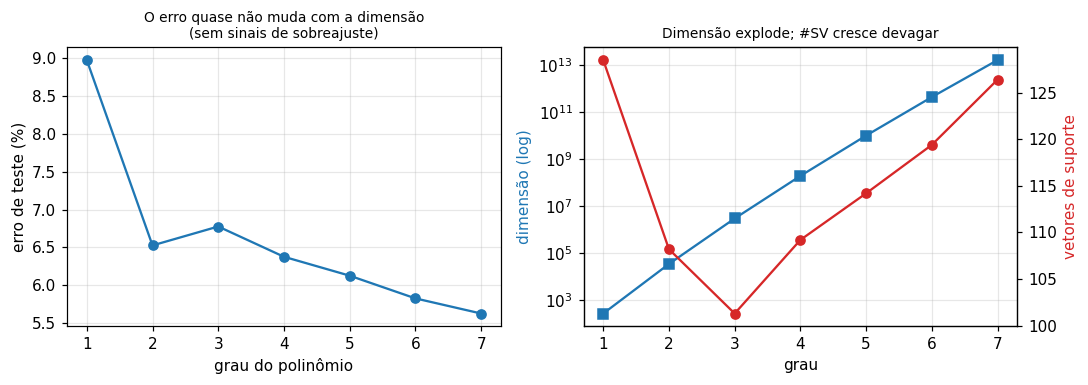

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ds = [r[0] for r in rows]
ax[0].plot(ds, [r[1] for r in rows], "o-"); ax[0].set_xlabel("grau do polinômio"); ax[0].set_ylabel("erro de teste (%)")
ax[0].set_title("O erro quase não muda com a dimensão\n(sem sinais de sobreajuste)", fontsize=9); ax[0].grid(alpha=.3)
ax[1].semilogy(ds, [r[3] for r in rows], "s-", label="dimensão do espaço"); ax[1].set_xlabel("grau")
ax[1].set_ylabel("dimensão (log)", color="C0")
ax1b = ax[1].twinx(); ax1b.plot(ds, [r[2] for r in rows], "o-", c="C3"); ax1b.set_ylabel("vetores de suporte", color="C3")
ax[1].set_title("Dimensão explode; #SV cresce devagar", fontsize=9); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Parte 5 — Limite de generalização, Eq. (5)

$$E[\Pr(\text{erro})]\le \frac{E[\#\text{vetores de suporte}]}{\#\text{vetores de treinamento}}$$

Como no artigo, é utilizado o **número observado** de vetores de suporte por classificador binário
(e não a esperança), e comparado com o erro de teste real **do mesmo classificador binário**.

In [9]:
d = 3
clf = ovr_poly(d).fit(Xtr_s, ytr)
print(f"Grau {d} — classificadores binários (um contra todos)")
print(f"{'Classe':>7} {'#SV':>6} {'#SV/ℓ (limite)':>15} {'erro teste real':>16} {'limite vale?':>13}")
for k, est in enumerate(clf.estimators_):
    nsv = est.n_support_.sum()
    bound = nsv / len(ytr)
    yb = (yte == k)                      # OneVsRest treina com rótulos 0/1
    err = np.mean(est.predict(Xte_s).astype(bool) != yb)
    print(f"{k:>7} {nsv:>6} {bound:>15.3%} {err:>16.3%} {str(err <= bound):>13}")

Grau 3 — classificadores binários (um contra todos)
 Classe    #SV  #SV/ℓ (limite)  erro teste real  limite vale?
      0     99          3.300%           1.146%          True
      1     85          2.833%           1.146%          True
      2     34          1.133%           0.797%          True
      3    134          4.467%           1.844%          True
      4    134          4.467%           1.893%          True
      5    115          3.833%           1.993%          True
      6    126          4.200%           1.744%          True
      7     81          2.700%           0.997%          True
      8     61          2.033%           1.146%          True
      9    144          4.800%           2.591%          True


## Parte 6 — Controle de capacidade com C (Seção 5.3)

$C$ pequeno ⇒ mais regularização (menor capacidade, mais erro de treinamento);
$C$ grande ⇒ aproxima o hiperplano ótimo. O gráfico mostra o compromisso do bound (38):
erro de treinamento + termo de confiança.

C=   0.01: erro treino=19.07%  erro teste=23.82%  SV médios=588
C=    0.1: erro treino= 6.33%  erro teste=10.86%  SV médios=384
C=      1: erro treino= 3.00%  erro teste= 7.42%  SV médios=197
C=     10: erro treino= 0.83%  erro teste= 6.18%  SV médios=127
C=    100: erro treino= 0.03%  erro teste= 6.78%  SV médios=101
C=   1000: erro treino= 0.00%  erro teste= 6.68%  SV médios=102


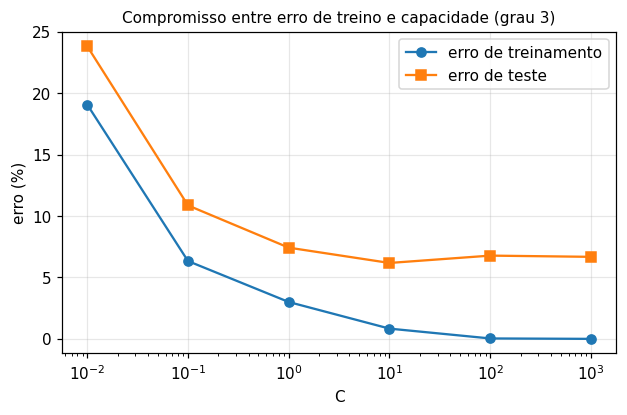

In [10]:
Cs = [1e-2, 1e-1, 1, 10, 100, 1000]
tr_err, te_err, nsvs = [], [], []
for C in Cs:
    clf = ovr_poly(3, C=C).fit(Xtr_s, ytr)
    tr_err.append(100 * (1 - clf.score(Xtr_s, ytr))); te_err.append(100 * (1 - clf.score(Xte_s, yte)))
    nsvs.append(sv_stats(clf))
    print(f"C={C:>7g}: erro treino={tr_err[-1]:5.2f}%  erro teste={te_err[-1]:5.2f}%  SV médios={nsvs[-1]:.0f}")

plt.figure(figsize=(6.5, 3.8))
plt.semilogx(Cs, tr_err, "o-", label="erro de treinamento")
plt.semilogx(Cs, te_err, "s-", label="erro de teste")
plt.xlabel("C"); plt.ylabel("erro (%)"); plt.grid(alpha=.3); plt.legend()
plt.title("Compromisso entre erro de treino e capacidade (grau 3)", fontsize=10); plt.show()

## Parte 7 — Base NIST/MNIST, grau 4, sem pré-processamento (Seção 6.2.2 / Tabela 3 / Fig. 9)

O artigo usa 60.000 treino e 10.000 teste (28×28 = 784 dimensões), polinômio de grau 4
**sem pré-processamento** e compara com classificador linear, k-NN (k=3) e redes LeNet.
Aqui comparamos SVN grau 4, linear e 3-NN. (As LeNets não são reproduzidas.)
Com `FAST=False` usa-se a base inteira (pode levar bastante tempo).

Base: MNIST (OpenML) | treino=6000 teste=3000 | n=784
SVN grau 4: 4.83% (24s)
Linear    : 11.83%
3-NN      : 5.53%

TABELA 3 (reprodução) — grau 4, por classificador binário
                Cl.0    Cl.1    Cl.2    Cl.3    Cl.4    Cl.5    Cl.6    Cl.7    Cl.8    Cl.9
 Supp. patt.     277     204     488     527     443     546     288     409     609     583
 Error train       0       0       0       0       1       0       0       2       1       5
  Error test      20      16      49      38      38      38      23      45      56      49
Razão média #SV/ℓ = 7.290%


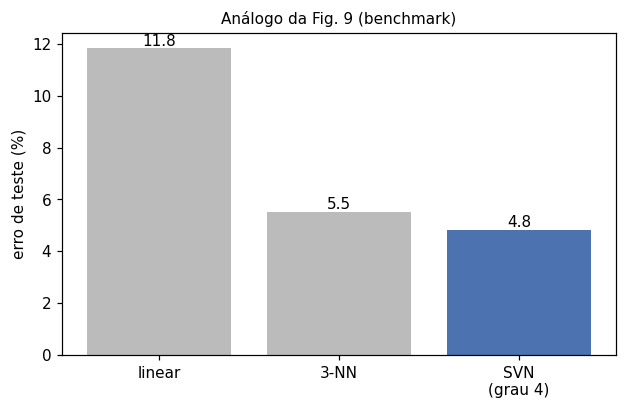

In [11]:
def load_mnist(ntr, nte):
    try:
        d = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
        X = d.data.astype(float) / 255.0; y = d.target.astype(int)
        Xa, ya, Xb, yb = X[:60000], y[:60000], X[60000:], y[60000:]
        r = np.random.default_rng(1)
        i, j = r.choice(60000, ntr, replace=False), r.choice(10000, nte, replace=False)
        return Xa[i], ya[i], Xb[j], yb[j], "MNIST (OpenML)"
    except Exception as e:
        print("Falha ao baixar MNIST (", type(e).__name__, "). Usando load_digits.")
        d = load_digits(); X = d.data / 16.0
        Xtr_, Xte_, ytr_, yte_ = train_test_split(X, d.target, test_size=0.3, random_state=0, stratify=d.target)
        return Xtr_, ytr_, Xte_, yte_, "load_digits 8x8 (alternativa)"

Xn_tr, yn_tr, Xn_te, yn_te, NAME2 = load_mnist(N_TRAIN_MNIST, N_TEST_MNIST)
nF = Xn_tr.shape[1]
print(f"Base: {NAME2} | treino={len(yn_tr)} teste={len(yn_te)} | n={nF}")

t0 = time.time()
svn4 = OneVsRestClassifier(SVC(kernel="poly", degree=4, gamma=1.0 / nF, coef0=1.0, C=C_LARGE, cache_size=800)).fit(Xn_tr, yn_tr)
e_svn = 100 * (1 - svn4.score(Xn_te, yn_te)); print(f"SVN grau 4: {e_svn:.2f}% ({time.time()-t0:.0f}s)")

lin_clf = LinearSVC(C=1.0, max_iter=5000).fit(Xn_tr, yn_tr)
e_lin = 100 * (1 - lin_clf.score(Xn_te, yn_te)); print(f"Linear    : {e_lin:.2f}%")

knn = KNeighborsClassifier(n_neighbors=3).fit(Xn_tr, yn_tr)
e_knn = 100 * (1 - knn.score(Xn_te, yn_te)); print(f"3-NN      : {e_knn:.2f}%")

# Tabela 3 (análogo)
print("\nTABELA 3 (reprodução) — grau 4, por classificador binário")
hdr = "".join(f"{'Cl.'+str(k):>8}" for k in range(10)); print(f"{'':>12}{hdr}")
sp, etr, ete = [], [], []
for k, est in enumerate(svn4.estimators_):
    sp.append(est.n_support_.sum())
    etr.append(int(np.sum(est.predict(Xn_tr).astype(bool) != (yn_tr == k))))
    ete.append(int(np.sum(est.predict(Xn_te).astype(bool) != (yn_te == k))))
for nm, v in [("Supp. patt.", sp), ("Error train", etr), ("Error test", ete)]:
    print(f"{nm:>12}" + "".join(f"{x:>8}" for x in v))
print(f"Razão média #SV/ℓ = {np.mean(sp)/len(yn_tr):.3%}")

plt.figure(figsize=(6.5, 3.8))
labs = ["linear", "3-NN", "SVN\n(grau 4)"]; vals = [e_lin, e_knn, e_svn]
bars = plt.bar(labs, vals, color=["#bbbbbb", "#bbbbbb", "#4c72b0"])
for b, v in zip(bars, vals): plt.text(b.get_x() + b.get_width()/2, v + .1, f"{v:.1f}", ha="center")
plt.ylabel("erro de teste (%)"); plt.title("Análogo da Fig. 9 (benchmark)", fontsize=10); plt.show()

## Parte 8 — Permutação aleatória dos pixels

O artigo cita (Bottou et al.): a SVN faria igualmente bem se os pixels fossem criptografados
por uma **permutação fixa e aleatória**, pois não usa conhecimento sobre a geometria da imagem.
Isso é consequência direta de $K(u,v)=(u\cdot v+1)^d$ depender só do produto escalar, que é
invariante a permutações das coordenadas. O k-NN com distância euclidiana também é invariante.

In [12]:
perm = rng.permutation(nF)
Xp_tr, Xp_te = Xn_tr[:, perm], Xn_te[:, perm]
svn4p = OneVsRestClassifier(SVC(kernel="poly", degree=4, gamma=1.0 / nF, coef0=1.0, C=C_LARGE, cache_size=800)).fit(Xp_tr, yn_tr)
e_svn_p = 100 * (1 - svn4p.score(Xp_te, yn_te))
e_knn_p = 100 * (1 - KNeighborsClassifier(n_neighbors=3).fit(Xp_tr, yn_tr).score(Xp_te, yn_te))
print(f"SVN grau 4  original: {e_svn:.2f}%  |  pixels permutados: {e_svn_p:.2f}%")
print(f"3-NN        original: {e_knn:.2f}%  |  pixels permutados: {e_knn_p:.2f}%")
print("\n(Diferenças ~0 confirmam a observação do artigo. Já uma CNN, que explora vizinhança espacial, seria prejudicada.)")

SVN grau 4  original: 4.83%  |  pixels permutados: 4.83%
3-NN        original: 5.53%  |  pixels permutados: 5.53%

(Diferenças ~0 confirmam a observação do artigo. Já uma CNN, que explora vizinhança espacial, seria prejudicada.)


## Conclusões para discussão

1. **Dimensão do espaço ≠ capacidade efetiva:** o erro quase não muda do grau 3 ao 7, mas a dimensão sobe várias ordens de grandeza.
2. **Esparsidade:** poucos vetores de suporte definem o classificador; a razão #SV/ℓ funciona como estimador do erro (Eq. 5).
3. **Margem suave:** C faz o compromisso entre erro de treino e complexidade (Seção 5.3).
4. **Kernel sem engenharia de atributos:** desempenho comparável a redes especializadas, sem conhecimento da geometria da imagem.
5. **Limitações:** o QP escala mal com ℓ (daí o *chunking* e métodos modernos como SMO), a escolha de kernel/hiperparâmetros é empírica
   e a extensão multiclasse (um contra todos) é heurística.

**Extensões sugeridas:** kernel RBF (`rbf_kernel`), busca de C e σ por validação cruzada, comparação com SVC multiclasse nativo,
acrescentar deslocamento/correção de inclinação (*deskewing*) e medir o ganho do pré-processamento.